In [1]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
from google.colab import files

uploaded = files.upload()

Saving Sample - Superstore.csv to Sample - Superstore.csv


In [3]:
import pandas as pd

df = pd.read_csv("Sample - Superstore.csv", encoding="latin1")

print("Dataset loaded successfully!")

display(df.head())

Dataset loaded successfully!


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [4]:
print("Rows and Columns:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Rows and Columns: (9994, 21)

Column Names:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   obj

In [5]:
# DATA CLEANING

# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Records:", df.duplicated().sum())

# Convert Order Date into datetime format
df["Order Date"] = pd.to_datetime(
    df["Order Date"],
    format="mixed"
)

# Check data types
print("\nData Types:")
print(df.dtypes)

print("\nData Cleaning Check Completed!")

Missing Values:
Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64

Duplicate Records: 0

Data Types:
Row ID                    int64
Order ID                 object
Order Date       datetime64[ns]
Ship Date                object
Ship Mode                object
Customer ID              object
Customer Name            object
Segment                  object
Country                  object
City                     object
State                    object
Postal Code               int64
Region                   object
Product ID               object
Category                 object
Sub-Category             object
Product Name             

In [7]:
# BUSINESS PERFORMANCE ANALYSIS

total_sales = df["Sales"].sum()

total_profit = df["Profit"].sum()

total_orders = df["Order ID"].nunique()

total_quantity = df["Quantity"].sum()

profit_margin = (total_profit / total_sales) * 100

print("===== BUSINESS PERFORMANCE =====")

print("Total Revenue: $", round(total_sales, 2))

print("Total Profit: $", round(total_profit, 2))

print("Total Orders:", total_orders)

print("Total Products Sold:", total_quantity)

print("Profit Margin:", round(profit_margin, 2), "%")

===== BUSINESS PERFORMANCE =====
Total Revenue: $ 2297200.86
Total Profit: $ 286397.02
Total Orders: 5009
Total Products Sold: 37873
Profit Margin: 12.47 %


In [8]:
# PROFIT BY CATEGORY

category_profit = df.groupby("Category")["Profit"].sum()

print("Profit by Category:")

display(category_profit.sort_values(ascending=False))

Profit by Category:


,Profit
Category,
Technology,145454.9481
Office Supplies,122490.8008
Furniture,18451.2728


In [9]:
# MONTHLY PROFIT ANALYSIS

df["Month"] = df["Order Date"].dt.to_period("M")

monthly_profit = df.groupby("Month")["Profit"].sum()

print("Monthly Profit:")

display(monthly_profit)

Monthly Profit:


,Profit
Month,
2014-01,2450.1907
2014-02,862.3084
2014-03,498.7299
2014-04,3488.8352
2014-05,2738.7096
2014-06,4976.5244
2014-07,-841.4826
2014-08,5318.1050
2014-09,8328.0994


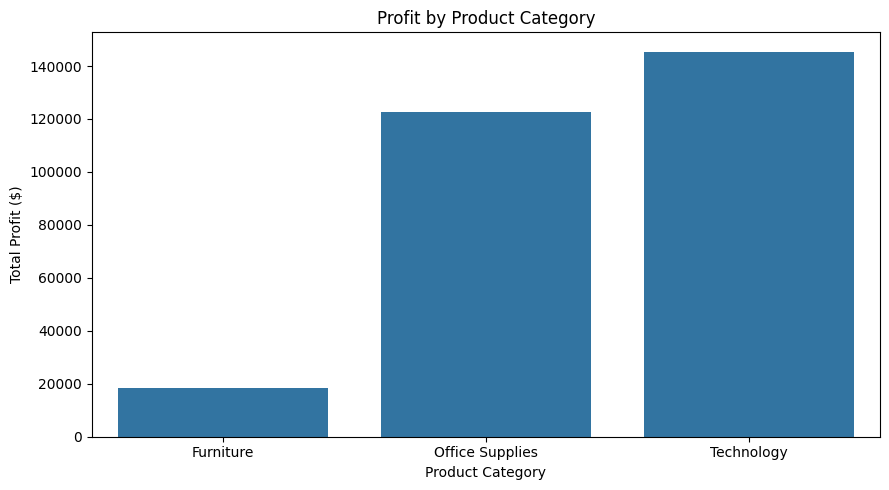

In [10]:
# PROFIT BY CATEGORY - BAR CHART

category_profit = df.groupby("Category")["Profit"].sum()

plt.figure(figsize=(9, 5))

sns.barplot(
    x=category_profit.index,
    y=category_profit.values
)

plt.title("Profit by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Profit ($)")

plt.tight_layout()
plt.show()

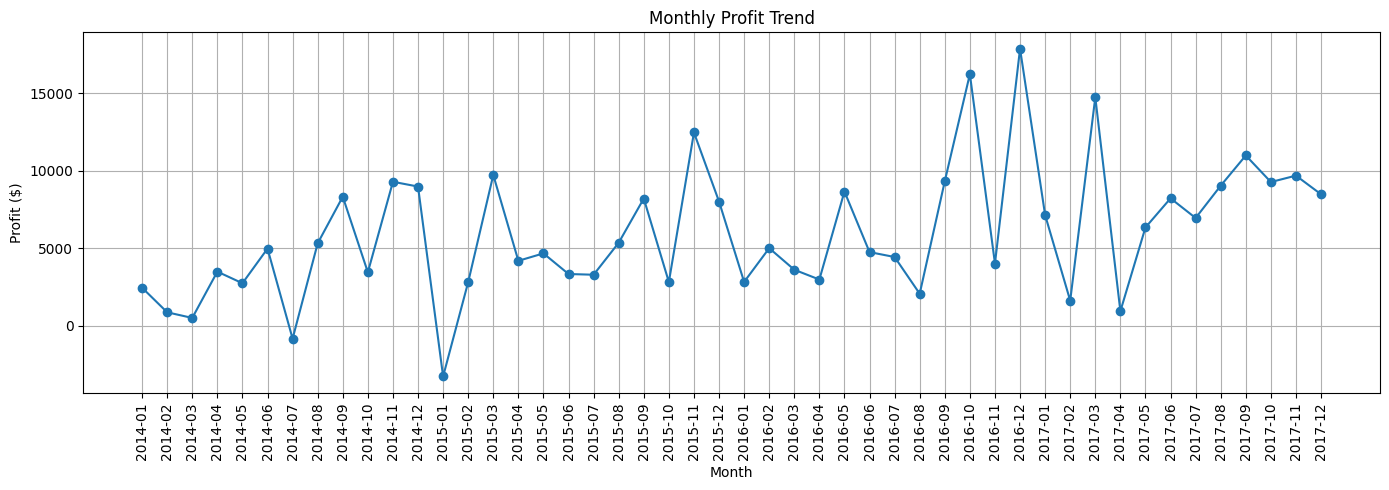

In [11]:
# MONTHLY PROFIT TREND

monthly_data = df.groupby(
    df["Order Date"].dt.to_period("M")
)["Profit"].sum()

plt.figure(figsize=(14, 5))

plt.plot(
    monthly_data.index.astype(str),
    monthly_data.values,
    marker="o"
)

plt.title("Monthly Profit Trend")
plt.xlabel("Month")
plt.ylabel("Profit ($)")

plt.xticks(rotation=90)
plt.grid(True)

plt.tight_layout()
plt.show()

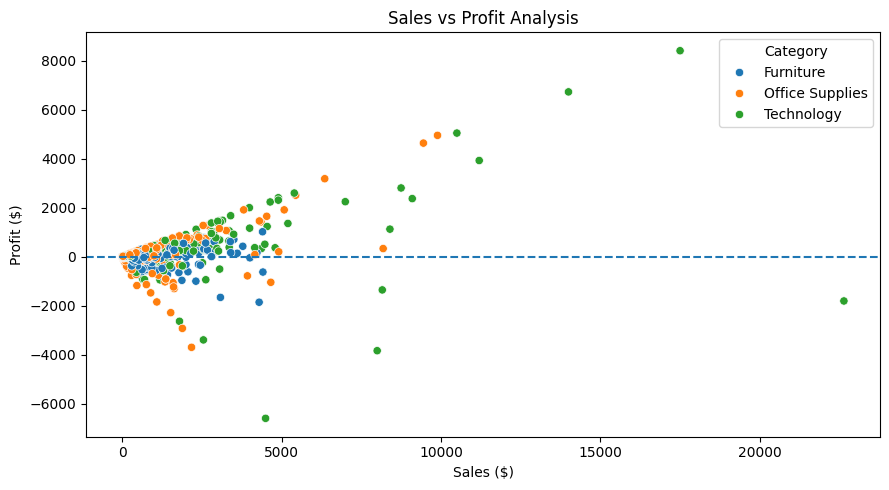

In [12]:
# SALES VS PROFIT

plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x="Sales",
    y="Profit",
    hue="Category"
)

plt.title("Sales vs Profit Analysis")
plt.xlabel("Sales ($)")
plt.ylabel("Profit ($)")

plt.axhline(0, linestyle="--")

plt.tight_layout()
plt.show()

In [13]:
# BUSINESS INSIGHTS ANALYSIS

# 1. Profit by Subcategory
subcategory_profit = df.groupby("Sub-Category")["Profit"].sum()

print("PROFIT BY SUBCATEGORY")
display(subcategory_profit.sort_values())

# 2. Profit by Region
region_profit = df.groupby("Region")["Profit"].sum()

print("\nPROFIT BY REGION")
display(region_profit.sort_values(ascending=False))

# 3. Loss-making Products
loss_products = df.groupby("Product Name")["Profit"].sum()

print("\nTOP 10 LOSS-MAKING PRODUCTS")
display(loss_products.sort_values().head(10))

# 4. Discount Analysis
discount_analysis = df.groupby("Discount")["Profit"].mean()

print("\nAVERAGE PROFIT BY DISCOUNT")
display(discount_analysis)

PROFIT BY SUBCATEGORY


,Profit
Sub-Category,
Tables,-17725.4811
Bookcases,-3472.5560
Supplies,-1189.0995
Fasteners,949.5182
Machines,3384.7569
Labels,5546.2540
Art,6527.7870
Envelopes,6964.1767
Furnishings,13059.1436



PROFIT BY REGION


,Profit
Region,
West,108418.4489
East,91522.7800
South,46749.4303
Central,39706.3625



TOP 10 LOSS-MAKING PRODUCTS


,Profit
Product Name,
Cubify CubeX 3D Printer Double Head Print,-8879.9704
Lexmark MX611dhe Monochrome Laser Printer,-4589.9730
Cubify CubeX 3D Printer Triple Head Print,-3839.9904
Chromcraft Bull-Nose Wood Oval Conference Tables & Bases,-2876.1156
Bush Advantage Collection Racetrack Conference Table,-1934.3976
GBC DocuBind P400 Electric Binding System,-1878.1662
Cisco TelePresence System EX90 Videoconferencing Unit,-1811.0784
Martin Yale Chadless Opener Electric Letter Opener,-1299.1836
Balt Solid Wood Round Tables,-1201.0581



AVERAGE PROFIT BY DISCOUNT


,Profit
Discount,
0.00,66.900292
0.10,96.055074
0.15,27.288298
0.20,24.702572
0.30,-45.679636
0.32,-88.560656
0.40,-111.927429
0.45,-226.646464
0.50,-310.703456
